# 09c track assignment

Rebuilds the cam_high hand tracks from the cached step 09 detections with a position based left/right assignment and compares them with the label based tracks.

## 1. setup

Imports and the settings that control the assignment.

In [1]:
import json
import os
import shutil
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm

# settings
MIN_SEP = 0.04
CONT_FRAMES = 15
AMBIG_MARGIN = 0.05
CONF_CUTOFF = 0.5
MIN_JOINTS = 15
COVERAGE_FLOOR_PCT = 30
JUMP_THRESHOLD = 0.2

CAM = "cam_high"
ASSIGN_TAG = "position_continuity_v1"
HANDS = ["left", "right"]

c:\workstation\3RD YEAR\ego_pipeline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1b. load config and caches

Reads the config files, the handedness mapping and the cached detections of every episode.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "configs" / "config.yaml").exists():
    raise RuntimeError("configs\\config.yaml not found in " + str(PROJECT_ROOT) + ", open the notebook from the notebooks folder")

REPORTS = PROJECT_ROOT / "reports"
EPISODES_DIR = PROJECT_ROOT / "episodes"
POSE_DIR = PROJECT_ROOT / "interim" / "pose"
REPORTS.mkdir(exist_ok=True)

with open(PROJECT_ROOT / "configs" / "config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

with open(PROJECT_ROOT / "configs" / "hand_layout.yaml", encoding="utf-8") as f:
    layout = yaml.safe_load(f)
joints = [str(j) for j in layout["joints"]]
mapping = {str(k): int(v) for k, v in layout["mediapipe_mapping"].items()}
bad = [k for k, v in mapping.items() if k not in joints or not 0 <= v <= 20]
if bad:
    raise RuntimeError("bad entries in mediapipe_mapping: " + ", ".join(bad))
mp_idx = np.array([mapping.get(j, -1) for j in joints])
mapped_joints = np.where(mp_idx >= 0)[0]
mp_sel = mp_idx[mapped_joints]
missing_joints = np.where(mp_idx < 0)[0]
wrist_names = [j for j in joints if mapping.get(j) == 0]
if not wrist_names:
    raise RuntimeError("no joint is mapped to mediapipe index 0 (wrist)")
WRIST_J = joints.index(wrist_names[0])

# label mapping from step 09, hand 0 = left and 1 = right
hc = pd.read_csv(REPORTS / "09_handedness_check.csv")
hc_row = hc[hc["camera"] == CAM]
if len(hc_row) == 0:
    raise RuntimeError("no row for " + CAM + " in 09_handedness_check.csv")
label_mapping = str(hc_row["mapping"].iloc[0]).strip().lower()
if label_mapping not in ("swap", "direct"):
    raise RuntimeError("unknown label mapping: " + label_mapping)
HAND_OF_LABEL = {0: 1, 1: 0} if label_mapping == "swap" else {0: 0, 1: 1}

with open(REPORTS / "06_summary.json", encoding="utf-8") as f:
    episodes = [str(e) for e in json.load(f)["episode_ids"]]

caches = {}
failed = {}
for ep in episodes:
    try:
        with np.load(POSE_DIR / f"{ep}_{CAM}.npz", allow_pickle=True) as z:
            c = {k: z[k] for k in ["det_frame", "det_label", "det_score", "det_presence", "det_lm", "n_frames", "limit"]}
            c["strategy"] = str(np.asarray(z["strategy"]).reshape(-1)[0]) if "strategy" in z.files else "?"
        caches[ep] = c
    except Exception as e:
        failed[ep] = f"cache: {e}"
        print(f"{ep}: {e}")

bad_limit = [ep for ep, c in caches.items() if int(np.asarray(c["limit"]).item()) != 0]
if bad_limit:
    raise RuntimeError("these caches are not full runs (limit is not 0): " + ", ".join(bad_limit))


def ok_eps():
    return [e for e in episodes if e not in failed]


rows = []
for ep, c in caches.items():
    _, cnt = np.unique(c["det_frame"], return_counts=True)
    rows.append({"episode_id": ep, "detections": len(c["det_frame"]),
                 "frames": int(np.asarray(c["n_frames"]).item()),
                 "frames_with_2": int((cnt >= 2).sum()), "strategy": c["strategy"]})
print("label mapping:", label_mapping, "| layout provisional:", layout.get("provisional"))
print("joints:", len(joints), "| mapped:", len(mapped_joints), "| wrist joint:", wrist_names[0])
print(pd.DataFrame(rows).to_string(index=False))

label mapping: swap | layout provisional: True
joints: 25 | mapped: 21 | wrist joint: wrist
                    episode_id  detections  frames  frames_with_2 strategy
vendorX_2026-10-11_op01_000001       41689   21240          20527     full
vendorX_2026-10-11_op01_000002       18600    9390           9230     full
vendorX_2026-10-11_op01_000003       20574   10410          10165     full
vendorX_2026-10-11_op01_000004       35588   18000          17609     full


## 2. old tracks

Loads the label based tracks and measures the baseline numbers. The first time, the old files are copied to hand_left_labelassign.npz and hand_right_labelassign.npz, and the baseline is always read from those copies.

In [3]:
def backup_tracks(ep):
    for h in HANDS:
        cur = EPISODES_DIR / ep / f"hand_{h}.npz"
        bak = EPISODES_DIR / ep / f"hand_{h}_labelassign.npz"
        if bak.exists():
            continue
        with np.load(cur, allow_pickle=True) as z:
            if "assignment" in z.files:
                raise RuntimeError(f"hand_{h}.npz is already a new track and has no backup")
        shutil.copy2(cur, bak)


def tracked_from_conf(conf):
    nv = (conf > 0).sum(axis=1)
    mean_conf = conf.sum(axis=1, dtype=np.float64) / np.maximum(nv, 1)
    return (nv >= MIN_JOINTS) & (mean_conf >= CONF_CUTOFF)


def load_track(path):
    with np.load(path, allow_pickle=True) as z:
        t = {k: z[k] for k in ["position", "confidence", "detected", "out_of_frame", "frame_index", "timestamp"]}
        # older step 09 files have no tracked array, so it is recomputed with the same rule
        t["tracked"] = z["tracked"].astype(bool) if "tracked" in z.files else tracked_from_conf(t["confidence"])
        t["joints"] = [str(j) for j in z["joints"]]
        t["position_tag"] = str(np.asarray(z["position_tag"]).reshape(-1)[0])
    return t


def wrist_xy(tr):
    return tr["position"][:, WRIST_J, :2].astype(np.float64)


def count_jumps(tr):
    w = wrist_xy(tr)
    det = tr["detected"].astype(bool)
    both = det[:-1] & det[1:] & (np.diff(tr["frame_index"]) == 1)
    with np.errstate(invalid="ignore"):
        d = np.hypot(w[1:, 0] - w[:-1, 0], w[1:, 1] - w[:-1, 1])
        return int((both & (d > JUMP_THRESHOLD)).sum())


def track_stats(left, right):
    wl = wrist_xy(left)[:, 0]
    wr = wrist_xy(right)[:, 0]
    # frames where both are tracked and both wrists have a position
    both = left["tracked"].astype(bool) & right["tracked"].astype(bool) & np.isfinite(wl) & np.isfinite(wr)
    n_both = int(both.sum())
    order_pct = float((wl[both] < wr[both]).mean() * 100) if n_both else np.nan
    return {"tracked_pct_left": float(left["tracked"].mean() * 100),
            "tracked_pct_right": float(right["tracked"].mean() * 100),
            "n_both": n_both, "order_pct": order_pct,
            "jumps_left": count_jumps(left), "jumps_right": count_jumps(right)}


old_tr = {}
base = {}
for ep in ok_eps():
    try:
        backup_tracks(ep)
        tr = {h: load_track(EPISODES_DIR / ep / f"hand_{h}_labelassign.npz") for h in HANDS}
        for h in HANDS:
            if tr[h]["joints"] != joints:
                raise ValueError(f"joint names of hand_{h} do not match the layout")
        old_tr[ep] = tr
        base[ep] = track_stats(tr["left"], tr["right"])
    except Exception as e:
        failed[ep] = f"old tracks: {e}"
        print(f"{ep}: {e}")

print(pd.DataFrame([{"episode_id": e, **base[e]} for e in ok_eps()]).round(2).to_string(index=False))

                    episode_id  tracked_pct_left  tracked_pct_right  n_both  order_pct  jumps_left  jumps_right
vendorX_2026-10-11_op01_000001             98.66              90.15   18948      99.95          22            3
vendorX_2026-10-11_op01_000002             99.40              89.23    8343      99.98          15            9
vendorX_2026-10-11_op01_000003             98.78              89.12    9151      99.77          68            6
vendorX_2026-10-11_op01_000004             99.09              89.47   15963      99.84          90           20


## 3. new assignment

Assigns the detections of each frame to the left or right hand by wrist position and continuity, builds the arrays like before and saves them over the old track files.

In [4]:
def label_pick(dets, label, score):
    # best scoring detection per hand from the label mapping
    out = {0: None, 1: None}
    for d in dets:
        h = HAND_OF_LABEL[int(label[d])]
        if out[h] is None or score[d] > score[out[h]]:
            out[h] = d
    return out


def assign_frames(cache, row_of, n):
    label = cache["det_label"]
    score = np.nan_to_num(cache["det_score"].astype(np.float64), nan=-1.0)
    wrist = cache["det_lm"][:, 0, :2].astype(np.float64)
    rows = np.array([row_of.get(int(f), -1) for f in cache["det_frame"]], dtype=np.int64)
    n_unknown = int((rows < 0).sum())
    valid = np.where(rows >= 0)[0]
    order = valid[np.argsort(rows[valid], kind="stable")]
    det_of = np.full((2, n), -1, dtype=np.int64)
    counts = {"sep": 0, "cont": 0, "label": 0}
    if len(order) == 0:
        return det_of, counts, n_unknown
    r_sorted = rows[order]
    starts = np.flatnonzero(np.r_[True, r_sorted[1:] != r_sorted[:-1]])
    ends = np.r_[starts[1:], len(order)]
    last = {0: None, 1: None}  # x, y, row of the last assigned wrist
    for s, e in zip(starts, ends):
        r = int(r_sorted[s])
        dets = sorted(order[s:e].tolist(), key=lambda d: -score[d])[:2]
        use_pos = bool(np.isfinite(wrist[dets]).all())
        recent = all(last[h] is not None and r - last[h][2] <= CONT_FRAMES for h in (0, 1))
        pick = None
        how = "label"
        if use_pos and len(dets) == 2:
            a, b = dets
            if abs(wrist[a, 0] - wrist[b, 0]) >= MIN_SEP:
                pick = {0: a, 1: b} if wrist[a, 0] < wrist[b, 0] else {0: b, 1: a}
                how = "sep"
            elif recent:
                def dist(d, h):
                    return float(np.hypot(wrist[d, 0] - last[h][0], wrist[d, 1] - last[h][1]))
                cost1 = dist(a, 0) + dist(b, 1)
                cost2 = dist(b, 0) + dist(a, 1)
                if cost1 != cost2:
                    pick = {0: a, 1: b} if cost1 < cost2 else {0: b, 1: a}
                    how = "cont"
        elif use_pos and len(dets) == 1 and recent:
            d = dets[0]
            dl = float(np.hypot(wrist[d, 0] - last[0][0], wrist[d, 1] - last[0][1]))
            dr = float(np.hypot(wrist[d, 0] - last[1][0], wrist[d, 1] - last[1][1]))
            if abs(dl - dr) >= AMBIG_MARGIN:
                pick = {0: d, 1: None} if dl < dr else {0: None, 1: d}
                how = "cont"
        if pick is None:
            pick = label_pick(dets, label, score)
            how = "label"
        counts[how] += 1
        for h in (0, 1):
            d = pick[h]
            if d is not None:
                det_of[h, r] = d
                if np.isfinite(wrist[d]).all():
                    last[h] = (wrist[d, 0], wrist[d, 1], r)
    return det_of, counts, n_unknown


def build_hand(cache, det_idx, old):
    n = len(det_idx)
    nj = len(joints)
    pos = np.full((n, nj, 3), np.nan, dtype=np.float32)
    conf = np.zeros((n, nj), dtype=np.float32)
    oof = np.zeros(n, dtype=bool)
    for r in np.flatnonzero(det_idx >= 0):
        d = det_idx[r]
        pts = cache["det_lm"][d][mp_sel].astype(np.float64)
        finite = np.isfinite(pts).all(axis=1)
        inside = (pts[:, 0] >= 0) & (pts[:, 0] <= 1) & (pts[:, 1] >= 0) & (pts[:, 1] <= 1)
        oof[r] = bool((finite & ~inside).any())
        c = float(np.fmin(cache["det_score"][d], cache["det_presence"][d]))
        if not np.isfinite(c) or c <= 0:
            continue
        good = finite & inside
        pos[r, mapped_joints[good]] = pts[good]
        conf[r, mapped_joints[good]] = c
    n_valid = (conf > 0).sum(axis=1)
    mean_conf = conf.sum(axis=1, dtype=np.float64) / np.maximum(n_valid, 1)
    tracked = (n_valid >= MIN_JOINTS) & (mean_conf >= CONF_CUTOFF)
    return {"position": pos, "confidence": conf, "detected": det_idx >= 0,
            "out_of_frame": oof, "tracked": tracked,
            "frame_index": old["frame_index"], "timestamp": old["timestamp"],
            "joints": joints, "position_tag": old["position_tag"]}


def save_tmp(path, tr):
    tmp = path.with_name(path.stem + ".tmp.npz")
    np.savez(tmp, position=tr["position"], confidence=tr["confidence"], detected=tr["detected"],
             out_of_frame=tr["out_of_frame"], tracked=tr["tracked"], frame_index=tr["frame_index"],
             timestamp=tr["timestamp"], joints=np.array(tr["joints"]),
             position_tag=np.array(tr["position_tag"]), assignment=np.array(ASSIGN_TAG))
    return tmp

In [5]:
new_tr = {}
assign_info = {}
for ep in tqdm(ok_eps(), desc="episodes"):
    try:
        c = caches[ep]
        n = len(old_tr[ep]["left"]["frame_index"])
        if len(old_tr[ep]["right"]["frame_index"]) != n or int(np.asarray(c["n_frames"]).item()) != n:
            raise ValueError("frame counts of the cache and the old tracks differ")
        row_of = {int(f): i for i, f in enumerate(old_tr[ep]["left"]["frame_index"])}
        det_of, counts, n_unknown = assign_frames(c, row_of, n)
        new = {h: build_hand(c, det_of[i], old_tr[ep][h]) for i, h in enumerate(HANDS)}
        for h in HANDS:
            if not (EPISODES_DIR / ep / f"hand_{h}_labelassign.npz").exists():
                raise RuntimeError("backup is missing, not overwriting")
        tmps = {h: save_tmp(EPISODES_DIR / ep / f"hand_{h}.npz", new[h]) for h in HANDS}
        for h in HANDS:
            os.replace(tmps[h], EPISODES_DIR / ep / f"hand_{h}.npz")
        new_tr[ep] = new
        assign_info[ep] = {"frames_with_detection": int((det_of >= 0).any(axis=0).sum()),
                           "unmatched_detections": n_unknown, **counts}
    except Exception as e:
        failed[ep] = f"assignment: {e}"
        print(f"{ep}: {e}")

for ep, info in assign_info.items():
    print(ep, info)

episodes: 100%|██████████| 4/4 [00:07<00:00,  1.96s/it]

vendorX_2026-10-11_op01_000001 {'frames_with_detection': 21162, 'unmatched_detections': 0, 'sep': 20527, 'cont': 564, 'label': 71}
vendorX_2026-10-11_op01_000002 {'frames_with_detection': 9370, 'unmatched_detections': 0, 'sep': 9230, 'cont': 129, 'label': 11}
vendorX_2026-10-11_op01_000003 {'frames_with_detection': 10409, 'unmatched_detections': 0, 'sep': 10165, 'cont': 207, 'label': 37}
vendorX_2026-10-11_op01_000004 {'frames_with_detection': 17979, 'unmatched_detections': 0, 'sep': 17609, 'cont': 329, 'label': 41}


## 4. coverage

Same coverage numbers as step 09 for the new tracks, next to the old tracked share.

In [6]:
if not ok_eps():
    raise RuntimeError("no episode has new tracks. reasons: " + "; ".join(f"{e}: {m}" for e, m in failed.items()))

# wrist_cam_detected_pct is copied from the old coverage file
old_cov = pd.read_csv(REPORTS / "09_coverage.csv")
if "camera" in old_cov.columns:
    old_cov = old_cov[old_cov["camera"] == CAM]
wrist_old = {}
if {"episode_id", "hand", "wrist_cam_detected_pct"} <= set(old_cov.columns):
    for _, r in old_cov.iterrows():
        hnd = str(r["hand"]).strip().lower()
        hnd = "left" if "left" in hnd else "right" if "right" in hnd else hnd
        wrist_old[(str(r["episode_id"]), hnd)] = r["wrist_cam_detected_pct"]
else:
    print("09_coverage.csv has no wrist_cam_detected_pct column, leaving it empty")

cov_rows = []
for ep in ok_eps():
    for h in HANDS:
        t = new_tr[ep][h]
        cov_rows.append({"episode_id": ep, "hand": h, "frames": len(t["tracked"]),
                         "detected_pct": t["detected"].mean() * 100,
                         "tracked_pct": t["tracked"].mean() * 100,
                         "out_of_frame_pct": t["out_of_frame"].mean() * 100})
cov = pd.DataFrame(cov_rows)
cov["low_coverage_flag"] = cov.groupby("episode_id")["tracked_pct"].transform("min") < COVERAGE_FLOOR_PCT
cov["wrist_cam_detected_pct"] = [wrist_old.get((e, h), np.nan) for e, h in zip(cov["episode_id"], cov["hand"])]
cov.round(3).to_csv(REPORTS / "09c_coverage.csv", index=False)

cmp = cov[["episode_id", "hand", "tracked_pct"]].copy()
cmp = cmp.rename(columns={"tracked_pct": "tracked_pct_new"})
cmp["tracked_pct_old"] = [old_tr[e][h]["tracked"].mean() * 100 for e, h in zip(cmp["episode_id"], cmp["hand"])]
print(cmp[["episode_id", "hand", "tracked_pct_old", "tracked_pct_new"]].round(2).to_string(index=False))

                    episode_id  hand  tracked_pct_old  tracked_pct_new
vendorX_2026-10-11_op01_000001  left            98.66            98.74
vendorX_2026-10-11_op01_000001 right            90.15            97.41
vendorX_2026-10-11_op01_000002  left            99.40            99.50
vendorX_2026-10-11_op01_000002 right            89.23            98.54
vendorX_2026-10-11_op01_000003  left            98.78            99.87
vendorX_2026-10-11_op01_000003 right            89.12            97.77
vendorX_2026-10-11_op01_000004  left            99.09            99.62
vendorX_2026-10-11_op01_000004 right            89.47            98.09


## 5. comparison

Per episode and hand: frames where the assignment changed, ordering of the wrists, wrist jumps and tracked share before and after.

In [7]:
def changed_mask(a, b):
    same = (a["position"] == b["position"]) | (np.isnan(a["position"]) & np.isnan(b["position"]))
    return ~same.all(axis=(1, 2)) | (a["detected"] != b["detected"])


after = {}
changed_any = {}
stat_rows = []
for ep in ok_eps():
    after[ep] = track_stats(new_tr[ep]["left"], new_tr[ep]["right"])
    masks = {h: changed_mask(old_tr[ep][h], new_tr[ep][h]) for h in HANDS}
    changed_any[ep] = int((masks["left"] | masks["right"]).sum())
    for h in HANDS:
        stat_rows.append({"episode_id": ep, "hand": h, "frames": len(masks[h]),
                          "frames_changed": int(masks[h].sum()),
                          "both_tracked_before": base[ep]["n_both"], "both_tracked_after": after[ep]["n_both"],
                          "ordering_pct_before": base[ep]["order_pct"], "ordering_pct_after": after[ep]["order_pct"],
                          "wrist_jumps_before": base[ep]["jumps_" + h], "wrist_jumps_after": after[ep]["jumps_" + h],
                          "tracked_pct_before": base[ep]["tracked_pct_" + h],
                          "tracked_pct_after": after[ep]["tracked_pct_" + h]})
stats = pd.DataFrame(stat_rows)
stats.round(3).to_csv(REPORTS / "09c_assignment_stats.csv", index=False)
print(stats.drop(columns=["frames", "both_tracked_before", "both_tracked_after"]).round(2).to_string(index=False))

                    episode_id  hand  frames_changed  ordering_pct_before  ordering_pct_after  wrist_jumps_before  wrist_jumps_after  tracked_pct_before  tracked_pct_after
vendorX_2026-10-11_op01_000001  left             155                99.95               100.0                  22                  2               98.66              98.74
vendorX_2026-10-11_op01_000001 right            1555                99.95               100.0                   3                  0               90.15              97.41
vendorX_2026-10-11_op01_000002  left              26                99.98               100.0                  15                  0               99.40              99.50
vendorX_2026-10-11_op01_000002 right             881                99.98               100.0                   9                  0               89.23              98.54
vendorX_2026-10-11_op01_000003  left             211                99.77               100.0                  68                  0        

## 6. figure

Wrist x and y of both hands for the first episode, first 60 seconds, old tracks on top and new tracks below.

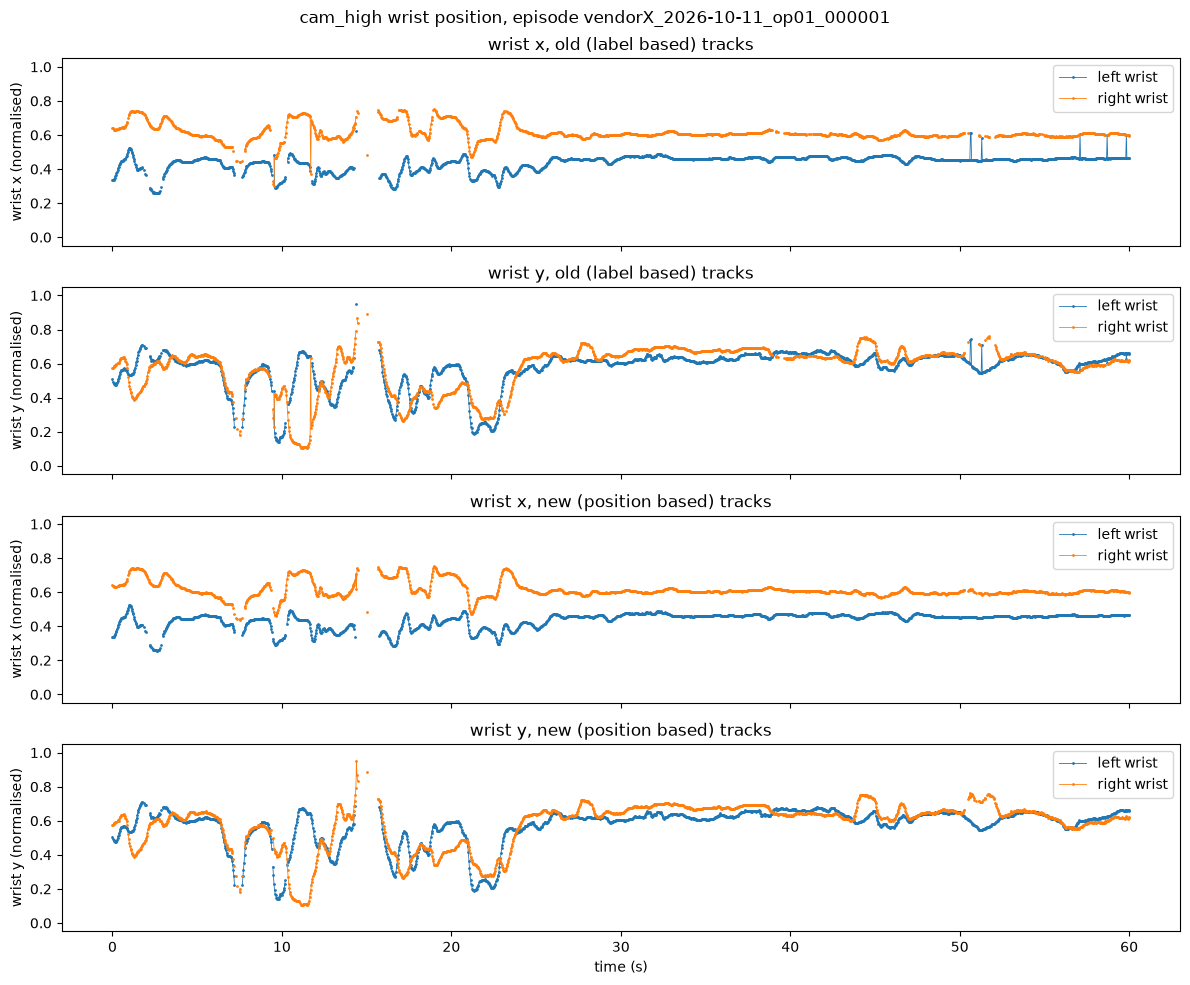

In [8]:
ep = ok_eps()[0]
ts = old_tr[ep]["left"]["timestamp"].astype(np.float64)
t = ts - np.nanmin(ts)
if not np.nanmedian(np.diff(t)) <= 0.5:
    # timestamps do not look like seconds, use frame index at 30 fps
    t = old_tr[ep]["left"]["frame_index"].astype(np.float64) / 30
    t = t - t[0]
sel = t <= 60

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
sets = [("old (label based)", old_tr[ep]), ("new (position based)", new_tr[ep])]
colors = {"left": "tab:blue", "right": "tab:orange"}
for k, (name, tr) in enumerate(sets):
    for c, coord in enumerate(["x", "y"]):
        ax = axes[2 * k + c]
        for h in HANDS:
            ax.plot(t[sel], wrist_xy(tr[h])[sel, c], color=colors[h], lw=0.6, marker=".", ms=2, label=h + " wrist")
        ax.set_title(f"wrist {coord}, {name} tracks")
        ax.set_ylabel(f"wrist {coord} (normalised)")
        ax.set_ylim(-0.05, 1.05)
        ax.legend(loc="upper right")
axes[-1].set_xlabel("time (s)")
fig.suptitle(f"{CAM} wrist position, episode {ep}")
fig.tight_layout()
fig.savefig(REPORTS / "09c_wrist_before_after.png", dpi=150)
plt.show()

## 7. hypothesis tests

Checks on the saved new tracks and on the comparison table.

In [9]:
disk = {e: {h: load_track(EPISODES_DIR / e / f"hand_{h}.npz") for h in HANDS} for e in ok_eps()}
tests = []


def add(tid, hyp, measured, result):
    tests.append({"id": tid, "hypothesis": hyp, "measured": measured, "result": result})


def verdict(ok):
    return "PASS" if ok else "FLAG"


# A1
bad = [f"{e}/{h}" for e in disk for h in HANDS
       if len(disk[e][h]["position"]) != len(old_tr[e][h]["position"])
       or len(disk[e][h]["frame_index"]) != len(old_tr[e][h]["frame_index"])]
add("A1", "every new track has the same number of frames as the old one",
    f"{len(bad)} of {2 * len(disk)} tracks differ", verdict(not bad))

# A2
n_bad = 0
for e in disk:
    for h in HANDS:
        p, cf = disk[e][h]["position"], disk[e][h]["confidence"]
        n_bad += int((np.isnan(p).any(axis=2) != (cf == 0)).sum())
add("A2", "position is NaN if and only if confidence is 0, every joint",
    f"{n_bad} joint values break the rule", verdict(n_bad == 0))

# A3
n_bad = 0
for e in disk:
    for h in HANDS:
        p, cf = disk[e][h]["position"], disk[e][h]["confidence"]
        n_bad += int((~np.isnan(p[:, missing_joints])).sum() + (cf[:, missing_joints] != 0).sum())
add("A3", "structurally missing joints are NaN with confidence 0 in every frame",
    f"{len(missing_joints)} missing joints, {n_bad} values break the rule", verdict(n_bad == 0))

# A4
n_bad = 0
for e in disk:
    for h in HANDS:
        p, cf = disk[e][h]["position"], disk[e][h]["confidence"]
        xy = p[..., :2][cf > 0]
        n_bad += int(((xy < 0) | (xy > 1)).sum())
add("A4", "positions of joints with confidence above 0 are inside [0,1]",
    f"{n_bad} coordinates outside", verdict(n_bad == 0))

# A5
order_ep = stats.groupby("episode_id")["ordering_pct_after"].first()
low = [e for e, v in order_ep.items() if not v >= 99]
add("A5", "ordering consistency after is at least 99 percent in every episode",
    f"lowest {order_ep.min():.2f} percent, {len(low)} episodes below", verdict(not low))

# A6
worse = stats[stats["wrist_jumps_after"] > stats["wrist_jumps_before"]]
add("A6", "wrist jumps after are not more than before for every episode and hand",
    f"{len(worse)} of {len(stats)} episode/hand pairs have more jumps", verdict(len(worse) == 0))

# A7
delta = stats["tracked_pct_after"] - stats["tracked_pct_before"]
add("A7", "tracked_pct after is not lower than before minus 0.5 points for every episode and hand",
    f"smallest change {delta.min():.2f} points, {int((delta < -0.5).sum())} pairs below", verdict(not (delta < -0.5).any()))

# A8
add("A8", "frames that changed assignment per episode",
    ", ".join(f"{e}: {changed_any[e]}" for e in changed_any), "INFO")

# A9
lowflag = sorted(cov.loc[cov["low_coverage_flag"], "episode_id"].unique())
add("A9", "low coverage flags", f"{len(lowflag)} episodes flagged" + (": " + ", ".join(lowflag) if lowflag else ""), "INFO")

hyp = pd.DataFrame(tests)
hyp.to_csv(REPORTS / "09c_hypothesis_check.csv", index=False)
print(hyp.to_string(index=False, max_colwidth=90))

id                                                                             hypothesis                                                                                   measured result
A1                           every new track has the same number of frames as the old one                                                                       0 of 8 tracks differ   PASS
A2                            position is NaN if and only if confidence is 0, every joint                                                              0 joint values break the rule   PASS
A3                   structurally missing joints are NaN with confidence 0 in every frame                                                  4 missing joints, 0 values break the rule   PASS
A4                           positions of joints with confidence above 0 are inside [0,1]                                                                      0 coordinates outside   PASS
A5                     ordering consistency after is at leas

## 8. summary

Writes the summary json and zips all 09c files in the reports folder.

In [10]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (float, np.floating)):
        v = float(o)
        return round(v, 4) if np.isfinite(v) else None
    return o


summary = {
    "camera": CAM,
    "assignment": ASSIGN_TAG,
    "label_mapping_before": label_mapping,
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "settings": {"MIN_SEP": MIN_SEP, "CONT_FRAMES": CONT_FRAMES, "AMBIG_MARGIN": AMBIG_MARGIN,
                 "CONF_CUTOFF": CONF_CUTOFF, "MIN_JOINTS": MIN_JOINTS,
                 "COVERAGE_FLOOR_PCT": COVERAGE_FLOOR_PCT, "JUMP_THRESHOLD": JUMP_THRESHOLD},
    "episodes_total": len(episodes),
    "episodes_done": ok_eps(),
    "episodes_failed": failed,
    "episodes": {e: {"frames_changed_any_hand": changed_any[e], "assignment_methods": assign_info[e],
                     "before": base[e], "after": after[e]} for e in ok_eps()},
    "tests": tests,
    "low_coverage_episodes": lowflag,
}
with open(REPORTS / "09c_summary.json", "w", encoding="utf-8") as f:
    json.dump(clean(summary), f, indent=2)

zip_path = REPORTS / "share_09c.zip"
files = sorted(p for p in REPORTS.glob("09c_*") if p.is_file())
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in files:
        zf.write(p, arcname=p.name)

print(f"episodes done: {len(ok_eps())} of {len(episodes)}")
for e in ok_eps():
    b, a = base[e], after[e]
    print(f"{e}: changed {changed_any[e]} frames, ordering {b['order_pct']:.1f} -> {a['order_pct']:.1f} percent, "
          f"jumps {b['jumps_left'] + b['jumps_right']} -> {a['jumps_left'] + a['jumps_right']}")
for e, msg in failed.items():
    print("failed:", e, msg)
print("tests:", ", ".join(f"{r} {int((hyp['result'] == r).sum())}" for r in ["PASS", "FLAG", "INFO"]))
print("zip:", zip_path, f"({len(files)} files)")

episodes done: 4 of 4
vendorX_2026-10-11_op01_000001: changed 1606 frames, ordering 100.0 -> 100.0 percent, jumps 25 -> 2
vendorX_2026-10-11_op01_000002: changed 890 frames, ordering 100.0 -> 100.0 percent, jumps 24 -> 0
vendorX_2026-10-11_op01_000003: changed 1035 frames, ordering 99.8 -> 100.0 percent, jumps 74 -> 0
vendorX_2026-10-11_op01_000004: changed 1689 frames, ordering 99.8 -> 100.0 percent, jumps 110 -> 0
tests: PASS 7, FLAG 0, INFO 2
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_09c.zip (5 files)
